# AP2 — Auditoria de modelos probabilísticos

**Pergunta de pesquisa:** o modelo probabilístico atribuído é adequado para representar o
comportamento da variável ou do evento analisado?

**Atribuição da investigação (registrada antes da análise):**

- **Variável atribuída pelo professor:** a variável qualitativa do grupo, Formato do Terreno
  (`Lot Shape`).
- **Trilha escolhida pelo grupo:** Binomial, com $n = 20$ seleções.
- **Evento:** terreno de formato irregular — `Lot Shape` diferente de `Reg`, ou seja, `IR1`,
  `IR2` ou `IR3`.

**Por que a trilha Binomial.** `Lot Shape` é uma variável qualitativa com categorias (`Reg`,
`IR1`, `IR2`, `IR3`). Ela não é uma contagem de ocorrências em um intervalo, o que afasta a
trilha Poisson, nem uma medida quantitativa contínua, o que afasta a trilha Normal. O que
cabe a uma variável qualitativa é transformá-la em um evento de dois resultados (aqui,
irregular ou não), cuja contagem em $n$ seleções é o objeto do modelo Binomial. Essa escolha
é registrada antes da análise e não será trocada em razão dos resultados.

**Convenção de nomes:** cada variável aparece com o **nome legível** seguido do **nome
original no arquivo entre parênteses**, como na AP1.

Este notebook cobre o carregamento dos dados e as etapas 1 a 3 do enunciado.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 120)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3


## Carregamento dos dados

Base única da AP2: `data/processed/AmesHousing.csv`, produzida na AP1. As decisões da AP1
(inclusive a exclusão dos imóveis fora das cercas de Tukey) não são redefinidas aqui.


In [2]:
df = pd.read_csv('data/processed/AmesHousing.csv')

print(f"Dimensões: {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Tipo de Formato do Terreno (Lot Shape): {df['Lot Shape'].dtype}")
print(f"Valores ausentes em Formato do Terreno (Lot Shape): {df['Lot Shape'].isna().sum()}")


Dimensões: 2757 linhas x 83 colunas
Tipo de Formato do Terreno (Lot Shape): str
Valores ausentes em Formato do Terreno (Lot Shape): 0


## 1. Delimitação da variável aleatória

**Unidade de análise.** Um imóvel residencial vendido em Ames, Iowa (EUA), entre 2006 e 2010,
identificado por `PID`. Na base tratada da AP1 há 2757 imóveis.

**Evento em linguagem natural.** O imóvel tem terreno de formato irregular, isto é,
Formato do Terreno (`Lot Shape`) é `IR1` (levemente irregular), `IR2` (moderadamente
irregular) ou `IR3` (irregular). O complemento é `Reg` (formato regular).

**Variável aleatória.** Para cada imóvel, o indicador do evento é

$$Y = \begin{cases} 1, & \text{se } \texttt{Lot Shape} \neq \texttt{Reg} \\ 0, & \text{se } \texttt{Lot Shape} = \texttt{Reg} \end{cases}$$

Em $n = 20$ seleções de imóveis, a variável aleatória de interesse é

$$X = Y_1 + Y_2 + \dots + Y_{20},$$

o **número de imóveis com terreno irregular entre os 20 selecionados**. Seus valores
possíveis são $\{0, 1, 2, \dots, 20\}$.

**Classificação.** $X$ é uma variável aleatória **discreta** (contagem de ocorrências do evento).

**Suporte observado e suporte previsto pelo modelo.**

- *Observado:* $X$ não é uma coluna do conjunto de dados; ela é definida pelas seleções. O
  que se observa nos dados é o indicador $Y$, com valores em $\{0, 1\}$ (verificado abaixo).
- *Previsto pelo modelo Binomial(20, $p$):* $\{0, 1, \dots, 20\}$.

**Pergunta específica.** O número de imóveis com terreno de formato irregular em 20
seleções do Ames Housing pode ser representado por uma Binomial(20, $p$), com $p$ igual à
frequência relativa observada de terrenos irregulares?


In [3]:
valido = df['Lot Shape'].notna()
y = (df.loc[valido, 'Lot Shape'] != 'Reg').astype(int)

print("Valores observados do indicador Y:", sorted(y.unique().tolist()))
print("Valores de Formato do Terreno (Lot Shape) na base:", sorted(df['Lot Shape'].unique().tolist()))


Valores observados do indicador Y: [0, 1]
Valores de Formato do Terreno (Lot Shape) na base: ['IR1', 'IR2', 'IR3', 'Reg']


## 2. Compatibilidade inicial do modelo atribuído

Síntese feita **antes** de qualquer cálculo ou comparação gráfica. Ela orienta a auditoria,
mas não antecipa o parecer final.

| Aspecto | O que o modelo Binomial(20, $p$) exige | Situação no Ames Housing |
|---|---|---|
| **Tipo da variável** | Variável discreta que conta ocorrências de um evento | $X$ conta imóveis com terreno irregular: discreta, compatível por definição |
| **Suporte** | $\{0, 1, \dots, 20\}$ | $X$ é a soma de 20 indicadores, logo fica em $\{0, \dots, 20\}$ por construção |
| **Mecanismo probabilístico** | Número fixo de ensaios, dois resultados por ensaio, probabilidade constante e independência | $n = 20$ é fixado pelo enunciado e há dois resultados bem definidos (irregular ou não). Probabilidade constante e independência dependem de como as seleções são feitas num conjunto finito de 2757 imóveis e de o evento ser igualmente provável em todos eles |
| **Parâmetros** | $n$ e $p$ | $n = 20$ é dado; $p$ será a frequência relativa observada de terrenos irregulares (calibração descritiva, etapa 4) |
| **Pressupostos essenciais** | Número fixo de ensaios, dois resultados, $p$ constante, independência | Os dois primeiros decorrem da definição do evento. Os dois últimos ainda não têm evidência e serão examinados na etapa 6 |


## 3. Descrição empírica

### 3.1 Observações válidas e valores ausentes


In [4]:
n_total = len(df)
n_validos = int(valido.sum())
n_ausentes = int((~valido).sum())

print(f"Observações no arquivo: {n_total}")
print(f"Observações válidas de Formato do Terreno (Lot Shape): {n_validos}")
print(f"Valores ausentes: {n_ausentes} ({n_ausentes / n_total * 100:.2f}%)")


Observações no arquivo: 2757
Observações válidas de Formato do Terreno (Lot Shape): 2757
Valores ausentes: 0 (0.00%)


### 3.2 Tabela de frequências relativas — Tabela 1


In [5]:
lot = df.loc[valido, 'Lot Shape']
n0 = int((y == 0).sum())
n1 = int((y == 1).sum())
N = len(y)

linhas = [
    ('Y = 0 — Regular (Reg)', n0),
    ('Y = 1 — Irregular (IR1, IR2 ou IR3)', n1),
    ('   dos quais IR1 (levemente irregular)', int((lot == 'IR1').sum())),
    ('   dos quais IR2 (moderadamente irregular)', int((lot == 'IR2').sum())),
    ('   dos quais IR3 (irregular)', int((lot == 'IR3').sum())),
    ('Total', N),
]

tabela1 = pd.DataFrame(
    {'Frequência absoluta': [v for _, v in linhas],
     'Frequência relativa (%)': [round(v / N * 100, 2) for _, v in linhas]},
    index=[nome for nome, _ in linhas],
)
tabela1.index.name = 'Evento: terreno irregular (Lot Shape)'
tabela1


,Frequência absoluta,Frequência relativa (%)
Evento: terreno irregular (Lot Shape),,
Y = 0 — Regular (Reg),1790,64.93
"Y = 1 — Irregular (IR1, IR2 ou IR3)",967,35.07
dos quais IR1 (levemente irregular),887,32.17
dos quais IR2 (moderadamente irregular),68,2.47
dos quais IR3 (irregular),12,0.44
Total,2757,100.00


### 3.3 Representação gráfica — Figura 1


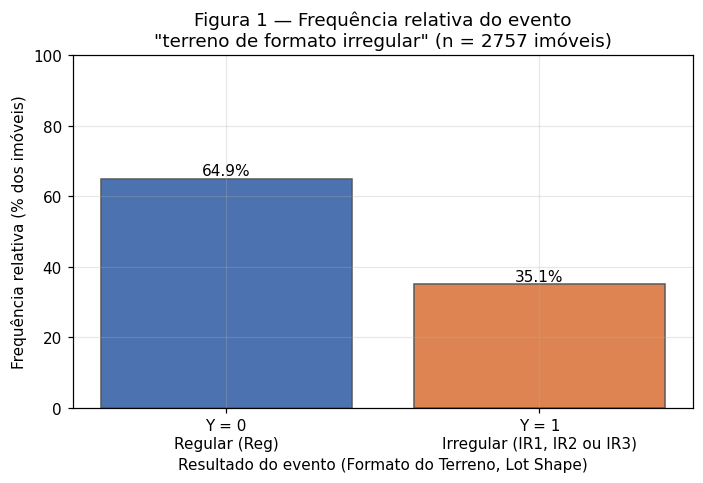

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
rotulos = ['Y = 0\nRegular (Reg)', 'Y = 1\nIrregular (IR1, IR2 ou IR3)']
freq_rel = [n0 / N * 100, n1 / N * 100]

ax.bar(rotulos, freq_rel, color=['#4C72B0', '#DD8452'], edgecolor='#595959')
for i, v in enumerate(freq_rel):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=10)

ax.set_ylim(0, 100)
ax.set_xlabel('Resultado do evento (Formato do Terreno, Lot Shape)')
ax.set_ylabel('Frequência relativa (% dos imóveis)')
ax.set_title('Figura 1 — Frequência relativa do evento\n"terreno de formato irregular" (n = 2757 imóveis)')
fig.tight_layout()
plt.show()


**Interpretação.** Cerca de dois terços dos imóveis têm terreno regular (64,9%) e cerca de um
terço tem terreno irregular (35,1%). O evento não é raro nem quase certo: os dois resultados
estão bem representados na base.

### 3.4 Média e variância observadas — Tabela 2


In [7]:
p_obs = y.mean()

tabela2 = pd.DataFrame({
    'Valor': {
        'Média de Y (= frequência relativa do evento)': p_obs,
        'Variância de Y (divisor n)': y.var(ddof=0),
        'Variância de Y (divisor n − 1)': y.var(ddof=1),
        'Desvio-padrão de Y (divisor n)': y.std(ddof=0),
        'Assimetria de Y': y.skew(),
    }
}).round(4)
tabela2.index.name = 'Medida do indicador Y'
tabela2


,Valor
Medida do indicador Y,
Média de Y (= frequência relativa do evento),0.3507
Variância de Y (divisor n),0.2277
Variância de Y (divisor n − 1),0.2278
Desvio-padrão de Y (divisor n),0.4772
Assimetria de Y,0.6259


A média de $Y$ é a frequência relativa observada do evento, $\hat p \approx 0{,}3507$.
Como $Y$ só assume 0 e 1, sua variância observada coincide com $\hat p\,(1-\hat p)$, e os dois
divisores (n e n − 1) diferem apenas na quarta casa decimal.

### 3.5 Características relevantes para a auditoria

- **Concentração.** O resultado mais frequente é o terreno regular (64,9%), mas o evento
  de interesse ocorre em 35,1% dos imóveis, longe dos extremos 0 e 1.
- **Composição do evento.** O evento reúne três categorias distintas: `IR1` responde por
  887 dos 967 imóveis irregulares (91,7%), `IR2` por 68 (7,0%) e `IR3` por 12 (1,2%).
- **Assimetria.** O indicador $Y$ tem assimetria positiva moderada (cerca de 0,63), efeito
  esperado de uma variável binária com frequência do evento abaixo de 50%.
- **Caudas e excesso de zeros.** Não se aplicam a um indicador binário: não há valores
  extremos além de 0 e 1, e o zero é simplesmente o resultado "terreno regular".
- **Limites naturais.** $Y$ está limitada a $\{0, 1\}$ e, nas 20 seleções, $X$ está limitada
  a $\{0, \dots, 20\}$, o mesmo suporte previsto pelo modelo.
- **Base finita.** Todas as frequências descrevem os 2757 imóveis da base tratada da AP1; não
  são estimativas para uma população maior.
